## K-means clustering

In [2]:
# Create some simple, grouped data
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=150,
                  n_features=2,
                  centers=3,
                  cluster_std=0.5,
                  shuffle=True,
                  random_state=0)

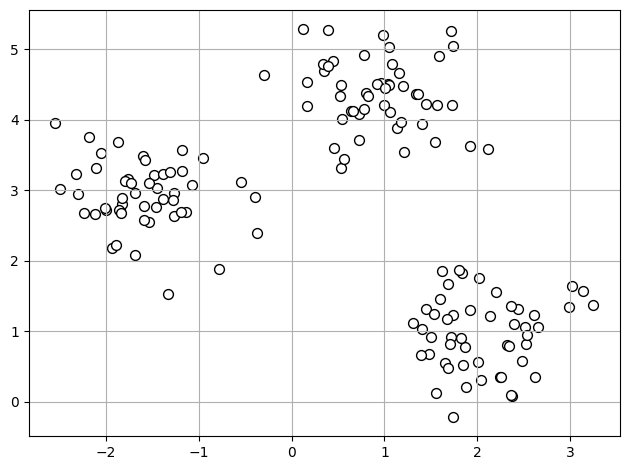

In [3]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1],
            c='white', marker='o', edgecolor='black', s=50)
plt.grid()
plt.tight_layout()
plt.show()

## K-means

In [4]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3,  # Check effect of mismatch with "centers" above!
            init='k-means++', # Type of initation (default = 'k-means++', alternatives 'random' or an array)
            n_init=10,     # Number of random starts, best fit wins, which means the algorithm will be run 10 times with different centroid seeds, and the final result will be the best one in terms of the inertia metric
            max_iter=300,  # the maximum number of iterations for each run of the algorithm. The default is 300.
            tol=1e-04,     # the relative tolerance with respect to inertia to declare convergence. The default is 1e-4.
            random_state=0)

y_km = km.fit_predict(X)

In [5]:
print(km.inertia_)
print(km.n_iter_)

72.47601670996696
3


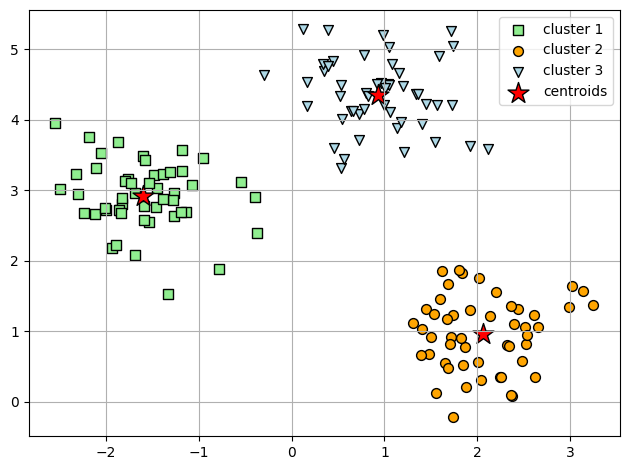

In [7]:
# Plot cluster 1
plt.scatter(X[y_km == 0, 0],
            X[y_km == 0, 1],
            s=50, c='lightgreen',
            marker='s', edgecolor='black',
            label='cluster 1')
# Plot cluster 2
plt.scatter(X[y_km == 1, 0],
            X[y_km == 1, 1],
            s=50, c='orange',
            marker='o', edgecolor='black',
            label='cluster 2')
# Plot cluster 3
plt.scatter(X[y_km == 2, 0],
            X[y_km == 2, 1],
            s=50, c='lightblue',
            marker='v', edgecolor='black',
            label='cluster 3')
# Plot cluster centres
plt.scatter(km.cluster_centers_[:, 0],
            km.cluster_centers_[:, 1],
            s=250, marker='*',
            c='red', edgecolor='black',
            label='centroids')
plt.legend(scatterpoints=1)
plt.grid()
plt.tight_layout()
plt.show()

Back to presentation

### Fuzzy clustering

In [6]:
# Cluster weights for each object
def w_update(X, centroids, m):
    """
    X : numpy array (#samples x #features)
    centroids : numpy array (#centroids x #features)
    m : fuzziness parameter
    """
    n = X.shape[0]
    c = centroids.shape[0]
    wn = np.zeros([n, c])  # Numerators
    w  = wn.copy()
    for j in range(c):
        wn[:,j] = np.sqrt(np.sum(np.power(X-centroids[j,:],2), axis=1)) # Eucledian distances
    for j in range(c):
        w += np.power(np.divide(wn, wn[:,j][:,np.newaxis]), 2/(m-1))    # Inverse cluster weights

    return np.power(w,-1) # Cluster weights

# Centroid update
def mu_update(X, w):
    """
    X : numpy array (#samples x #features)
    w : numpy array (#samples x #centroids)
    """
    return np.divide(w.T @ X, np.sum(w,axis=0)[:,np.newaxis])

# Objective function
def J_update(X, mu, w):
    """
    X : numpy array (#samples x #features)
    mu : numpy array(#centroids x #features)
    w : numpy array (#samples x #centroids)
    """
    J = 0
    for j in range(mu.shape[0]):
        J += (w[:,j].T @ np.sum(np.power(X-mu[j,:],2), axis=1)) # Weighted cluster inertia
    return J

In [19]:
import numpy as np
def FCM(X, c=3, m=2, max_iter=200, tol=10**-3):
    """
    X : numpy array - input data
    c : integer - number of clusters
    m : float - fuzziness
    max_iter : integer
    tol : float - inertia
    """
    [n, p] = X.shape

    # Initial centroids, weights, inertia
    centroids = X[np.random.choice(n, c, replace=False), :] + np.random.normal(0,np.max(X)/1000, [c,p])
    weights   = w_update(X, centroids, m)
    iters     = 0
    inertia   = tol
    p_inertia = -tol

    # Fuzzy c-means loop
    while abs(p_inertia - inertia) > tol and iters < max_iter:
        centroids = mu_update(X, weights)
        weights   = w_update(X, centroids, m)
        p_inertia = inertia
        inertia   = J_update(X, centroids, weights)
        iters    += 1

    cluster = np.argmax(weights, axis=1)
    return cluster, weights, centroids, inertia, iters

In [20]:
# Apply to the cluster problem
[cluster, weights, centroids, inertia, iters] = FCM(X)

### Plot clusters

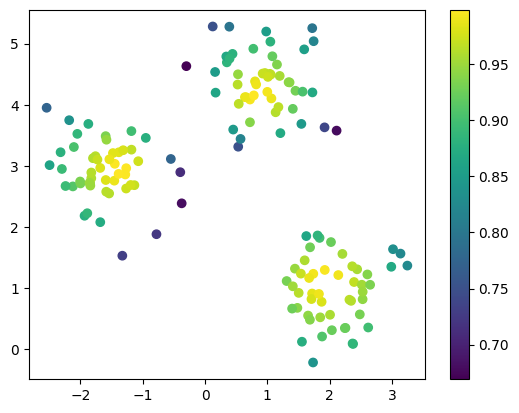

In [21]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0],X[:,1], c=np.max(weights, axis=1))
plt.colorbar()
plt.show()

Back to presentation

### Optimal number of clusters

In [11]:
print('Distortion: %.2f' % km.inertia_)

Distortion: 72.48


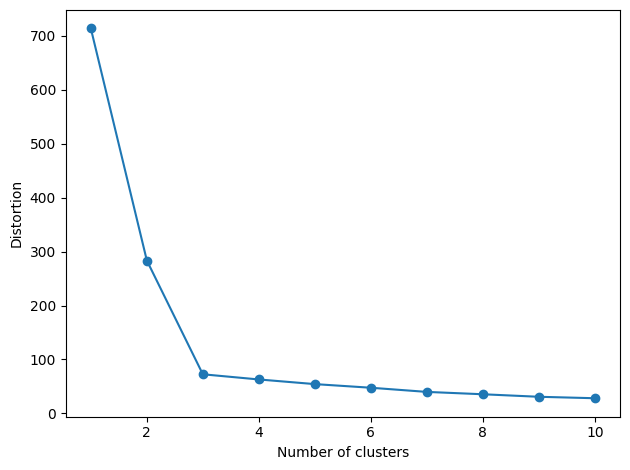

In [12]:
distortions = []
for i in range(1, 11):
    km = KMeans(n_clusters=i,
                init='k-means++',
                n_init=10,
                max_iter=300,
                random_state=0)
    km.fit(X)
    distortions.append(km.inertia_)
plt.plot(range(1, 11), distortions, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.tight_layout()
plt.show()

This data set was quite well separated, so the elbow is easily spotted.

Back to presentation

### Silhouette plots

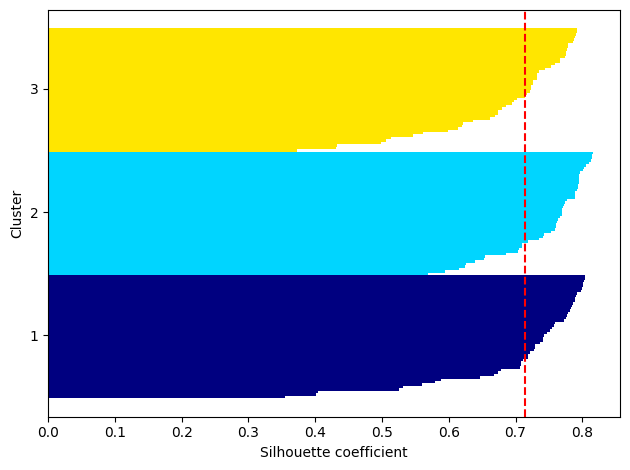

In [13]:
import numpy as np
from matplotlib import cm
from sklearn.metrics import silhouette_samples

# Clustering
km = KMeans(n_clusters=3,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-04,
            random_state=0)
y_km = km.fit_predict(X)

# Silhouette values
cluster_labels = np.unique(y_km)
n_clusters = cluster_labels.shape[0]
silhouette_vals = silhouette_samples(X, y_km, metric='euclidean') # Silhouette computations

# Silhouette plots
y_ax_lower, y_ax_upper = 0, 0
yticks = []
for i, c in enumerate(cluster_labels):
    c_silhouette_vals = silhouette_vals[y_km == c] # Extract for each class and
    c_silhouette_vals.sort()                       # sort them
    y_ax_upper += len(c_silhouette_vals)
    color = cm.jet(float(i) / n_clusters)
    # Barplot with fixed y-range and sorted silhouette values for class
    plt.barh(range(y_ax_lower, y_ax_upper), c_silhouette_vals, height=1.0,
             edgecolor='none', color=color)

    yticks.append((y_ax_lower + y_ax_upper) / 2.)
    y_ax_lower += len(c_silhouette_vals)

silhouette_avg = np.mean(silhouette_vals)

# Plot vertical line at mean silhouette value
plt.axvline(silhouette_avg, color="red", linestyle="--")

plt.yticks(yticks, cluster_labels + 1)
plt.ylabel('Cluster')
plt.xlabel('Silhouette coefficient')

plt.tight_layout()
plt.show()

Comparison to "bad" clustering:

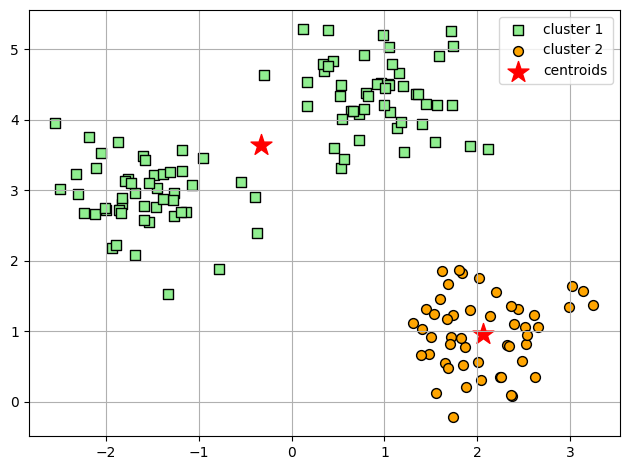

In [14]:
km = KMeans(n_clusters=2,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-04,
            random_state=0)
y_km = km.fit_predict(X)

plt.scatter(X[y_km == 0, 0],
            X[y_km == 0, 1],
            s=50,
            c='lightgreen',
            edgecolor='black',
            marker='s',
            label='cluster 1')
plt.scatter(X[y_km == 1, 0],
            X[y_km == 1, 1],
            s=50,
            c='orange',
            edgecolor='black',
            marker='o',
            label='cluster 2')

plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            s=250, marker='*', c='red', label='centroids')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

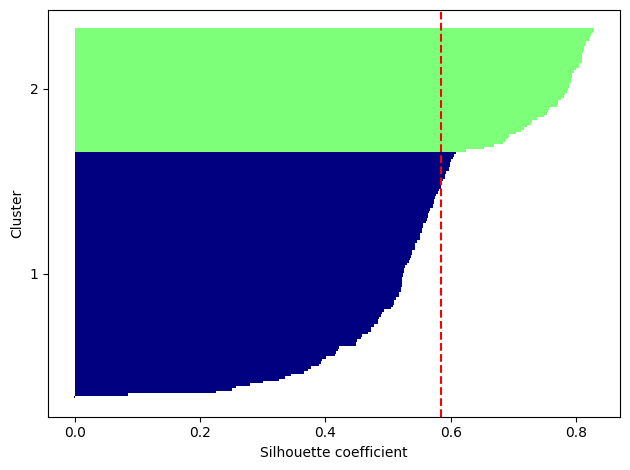

In [15]:
cluster_labels = np.unique(y_km)
n_clusters = cluster_labels.shape[0]
silhouette_vals = silhouette_samples(X, y_km, metric='euclidean')
y_ax_lower, y_ax_upper = 0, 0
yticks = []
for i, c in enumerate(cluster_labels):
    c_silhouette_vals = silhouette_vals[y_km == c]
    c_silhouette_vals.sort()
    y_ax_upper += len(c_silhouette_vals)
    color = cm.jet(float(i) / n_clusters)
    plt.barh(range(y_ax_lower, y_ax_upper), c_silhouette_vals, height=1.0,
             edgecolor='none', color=color)

    yticks.append((y_ax_lower + y_ax_upper) / 2.)
    y_ax_lower += len(c_silhouette_vals)

silhouette_avg = np.mean(silhouette_vals)
plt.axvline(silhouette_avg, color="red", linestyle="--")

plt.yticks(yticks, cluster_labels + 1)
plt.ylabel('Cluster')
plt.xlabel('Silhouette coefficient')

plt.tight_layout()
plt.show()

Back to presentation